# **Montesinho Fire Prediction System**
## **Notebook 04:** Weather Enrichment, Feature Engineering, and Preprocessing

---
## 1. Environment Setup, Relative Paths, and Plotting Style


In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.precision", 3)

# Configure clean, readable matplotlib styling
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["grid.linestyle"] = "--"

NAVY = "#17324D"
BLUE = "#2878B5"
ORANGE = "#F28E2B"
RED = "#D1495B"
GREEN = "#2A9D8F"
GREY = "#6B7280"

# Resolve relative project root whether running from 03_FINAL_SGIF_NOTEBOOKS/ or workspace root
if Path("data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv").exists():
    PROJECT_ROOT = Path(".")
elif Path("03_FINAL_SGIF_NOTEBOOKS/data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv").exists():
    PROJECT_ROOT = Path("03_FINAL_SGIF_NOTEBOOKS")
elif Path("../data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv").exists():
    PROJECT_ROOT = Path("..")
else:
    PROJECT_ROOT = Path(".")

EVENTS_PATH = PROJECT_ROOT / "data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv"
WEATHER_RAW_DIR = PROJECT_ROOT / "Dataset/nasa_power_hourly"
WEATHER_MANIFEST_PATH = PROJECT_ROOT / "data/reference/nasa_power/SOURCE_MANIFEST.json"
INTERIM_DIR = PROJECT_ROOT / "data/interim/nasa_power"
PROCESSED_DIR = PROJECT_ROOT / "data/processed/icnf_sgif"
TABLE_DIR = PROJECT_ROOT / "reports/tables/icnf_sgif"
FIGURE_DIR = PROJECT_ROOT / "reports/figures/icnf_sgif"

for directory in [INTERIM_DIR, PROCESSED_DIR, TABLE_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def nearest_native_cell(values, spacing):
    # Snap latitude or longitude values to the nearest NASA POWER MERRA-2 grid center
    numeric_values = pd.to_numeric(values, errors="coerce")
    return (np.floor(numeric_values / spacing + 0.5) * spacing).round(3)


print("=" * 72)
print("NOTEBOOK 04 ENVIRONMENT & PATH CONFIGURATION")
print("=" * 72)
print(f"Audited SGIF Events Input : {EVENTS_PATH.as_posix()}")
print(f"NASA POWER Manifest Input : {WEATHER_MANIFEST_PATH.as_posix()}")
print(f"Interim Weather Output Dir: {INTERIM_DIR.as_posix()}")
print(f"Processed Model Output Dir: {PROCESSED_DIR.as_posix()}")
print(f"Tables Output Dir         : {TABLE_DIR.as_posix()}")
print(f"Figures Output Dir        : {FIGURE_DIR.as_posix()}")


NOTEBOOK 04 ENVIRONMENT & PATH CONFIGURATION
Audited SGIF Events Input : data/interim/icnf_sgif/montesinho_events_2004_2025_audited.csv
NASA POWER Manifest Input : data/reference/nasa_power/SOURCE_MANIFEST.json
Interim Weather Output Dir: data/interim/nasa_power
Processed Model Output Dir: data/processed/icnf_sgif
Tables Output Dir         : reports/tables/icnf_sgif
Figures Output Dir        : reports/figures/icnf_sgif


---
## 2. NASA POWER Weather Source and Raw-File Audit


In [2]:
manifest = json.loads(WEATHER_MANIFEST_PATH.read_text(encoding="utf-8"))

print("=" * 72)
print("NASA POWER SOURCE MANIFEST CHECK")
print("=" * 72)
print(f"Manifest Time Standard : {manifest['time_standard']}")
print(f"Manifest Parameters    : {manifest['parameters']}")

weather_parts = []
raw_audit_rows = []

for item in manifest["files"]:
    rel_file = item["file"].replace("data/raw/nasa_power_hourly", "Dataset/nasa_power_hourly")
    path = PROJECT_ROOT / rel_file
    payload = json.loads(path.read_text(encoding="utf-8"))
    parameters = payload["properties"]["parameter"]
    timestamps = list(parameters["T2M"].keys())

    part = pd.DataFrame({
        "weather_time_utc": pd.to_datetime(timestamps, format="%Y%m%d%H", utc=True),
        "weather_grid_lat": item["latitude"],
        "weather_grid_lon": item["longitude"],
        "weather_temp_c": [parameters["T2M"][key] for key in timestamps],
        "weather_rh_pct": [parameters["RH2M"][key] for key in timestamps],
        "weather_wind_mps": [parameters["WS10M"][key] for key in timestamps],
        "weather_rain_mm_hour": [parameters["PRECTOTCORR"][key] for key in timestamps],
    })

    fill_value = payload["header"].get("fill_value", -999)
    weather_value_cols = ["weather_temp_c", "weather_rh_pct", "weather_wind_mps", "weather_rain_mm_hour"]
    part[weather_value_cols] = part[weather_value_cols].replace(fill_value, np.nan)
    weather_parts.append(part)

    raw_audit_rows.append({
        "file": path.name,
        "bytes": path.stat().st_size,
        "timestamps": len(part),
        "latitude": item["latitude"],
        "longitude": item["longitude"],
        "start_year": item["start_year"],
        "end_year": item["end_year"],
        "sha256": item["sha256"],
    })

raw_audit = pd.DataFrame(raw_audit_rows)

weather = (
    pd.concat(weather_parts, ignore_index=True)
    .sort_values(["weather_grid_lat", "weather_grid_lon", "weather_time_utc"])
    .drop_duplicates(["weather_grid_lat", "weather_grid_lon", "weather_time_utc"])
    .reset_index(drop=True)
)

# Compute rolling 6-hour and 24-hour accumulated rainfall within each grid cell
weather["weather_rain_mm_prev_6h"] = (
    weather.groupby(["weather_grid_lat", "weather_grid_lon"])["weather_rain_mm_hour"]
    .rolling(window=6, min_periods=6)
    .sum()
    .reset_index(level=[0, 1], drop=True)
)

weather["weather_rain_mm_prev_24h"] = (
    weather.groupby(["weather_grid_lat", "weather_grid_lon"])["weather_rain_mm_hour"]
    .rolling(window=24, min_periods=24)
    .sum()
    .reset_index(level=[0, 1], drop=True)
)

raw_audit.to_csv(TABLE_DIR / "weather_raw_file_audit.csv", index=False)

unique_cells = weather[["weather_grid_lat", "weather_grid_lon"]].drop_duplicates()
print(f"Raw JSON files audited : {len(raw_audit):,}")
print(f"Unique grid cell-hours : {len(weather):,}")
print(f"Distinct grid cells    : {len(unique_cells)}")
print(f"UTC time coverage      : {weather['weather_time_utc'].min()} to {weather['weather_time_utc'].max()}")
print("\nRaw File Audit Summary:")
display(raw_audit)


NASA POWER SOURCE MANIFEST CHECK
Manifest Time Standard : UTC
Manifest Parameters    : {'T2M': 'Temperature at 2 metres (degrees Celsius)', 'RH2M': 'Relative humidity at 2 metres (percent)', 'WS10M': 'Wind speed at 10 metres (metres per second)', 'PRECTOTCORR': 'Corrected precipitation; interpreted as mm/hour for hourly API output per API documentation'}
Raw JSON files audited : 15
Unique grid cell-hours : 569,808
Distinct grid cells    : 4
UTC time coverage      : 2004-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00

Raw File Audit Summary:


,file,bytes,timestamps,latitude,longitude,start_year,end_year,sha256
0,power_hourly_lat+41.500_lon-006.875_2007_2011.json,3191620,43824,41.5,-6.875,2007,2011,35c9409b8691b4a8a8916676050413cd9fd75634255b60ca0596fd1f7ca922e0
1,power_hourly_lat+41.500_lon-006.875_2012_2016.json,3193168,43848,41.5,-6.875,2012,2016,7620b8e092d07d74fa76883ca5e0118a7e483fd7cae139d492c52eda5bab4562
2,power_hourly_lat+41.500_lon-006.875_2017_2020.json,2554467,35064,41.5,-6.875,2017,2020,6f6cc76e93e0621f81ef5f7514832d8fa7f509d7839ec941798ccdf7b5a2ea68
3,power_hourly_lat+42.000_lon-007.500_2017_2021.json,3193579,43824,42.0,-7.500,2017,2021,b9288554b7b2ece356a222e0b7de57b90cf81b31d502613b0e75b0f0c33b610d
4,power_hourly_lat+42.000_lon-007.500_2022_2023.json,1278543,17520,42.0,-7.500,2022,2023,eef468ab663ed9c80a021882f4ee9c81b03ac0b1f6c764f0e76bf5788d06ca24
5,power_hourly_lat+42.000_lon-006.875_2004_2008.json,3191937,43848,42.0,-6.875,2004,2008,388b5ae17ae879eb6089c699f1e6173721f936eca99c461d1a8ab338592080d6
6,power_hourly_lat+42.000_lon-006.875_2009_2013.json,3191389,43824,42.0,-6.875,2009,2013,ae972b83af4d4b53430e735f8d9fbc839b4aee44c3e0bd6fc15dae72ad0b8bc7
7,power_hourly_lat+42.000_lon-006.875_2014_2018.json,3190289,43824,42.0,-6.875,2014,2018,fe0583bd6efd2b1d87be6f8190cb3a55b0ed5b8979a70be4a38d873de55121dd
8,power_hourly_lat+42.000_lon-006.875_2019_2023.json,3192025,43824,42.0,-6.875,2019,2023,ab68e4468123c7924eca2a76cc92ac8766d595fe81d933f4e490c5cb487fd367
9,power_hourly_lat+42.000_lon-006.875_2024_2025.json,1278748,17544,42.0,-6.875,2024,2025,21afd2d6fc08222392a646b70123a080668bf5040f6e19f2fc71ca24be870fcc


---
## 3. Leakage-Safe Event-Weather Join


LEAKAGE-SAFE EVENT-WEATHER JOIN VERIFICATION
Input SGIF events      : 1,644
Joined event records   : 1,644
Unique Codigo_SGIF IDs : 1,644
RH within [0, 100]%    : True
Wind speed >= 0 m/s    : True
Hourly rain >= 0 mm    : True
Max weather ref vs UTC : True (100% strictly pre-alert)


,field,matched_records,missing_records,coverage_pct
0,weather_temp_c,1644,0,100.0
1,weather_rh_pct,1644,0,100.0
2,weather_wind_mps,1644,0,100.0
3,weather_rain_mm_hour,1644,0,100.0
4,weather_rain_mm_prev_6h,1644,0,100.0
5,weather_rain_mm_prev_24h,1644,0,100.0


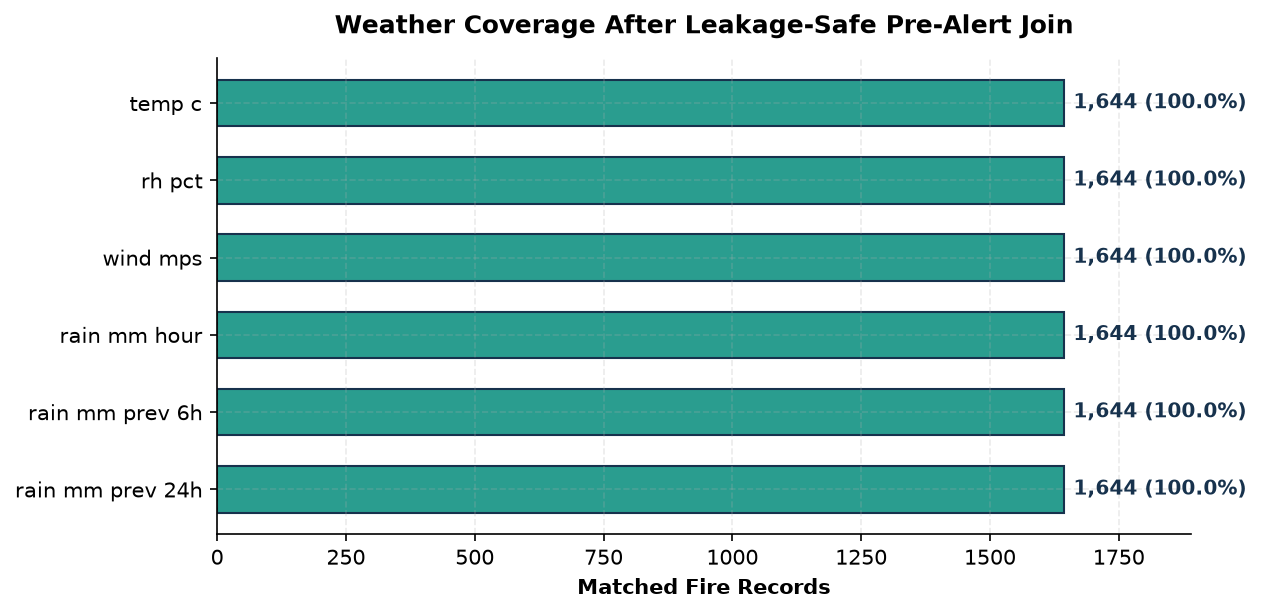

In [3]:
events = pd.read_csv(EVENTS_PATH, low_memory=False)

# 1. Convert Portuguese local civil alert timestamp to UTC
events["alert_time_local"] = pd.to_datetime(events["DataHoraAlerta"], errors="raise")
events["alert_time_utc"] = (
    events["alert_time_local"]
    .dt.tz_localize("Europe/Lisbon", ambiguous="raise", nonexistent="raise")
    .dt.tz_convert("UTC")
)

# 2. Select the most recent fully completed UTC hour prior to the alert
events["weather_reference_utc"] = events["alert_time_utc"].dt.floor("h") - pd.Timedelta(hours=1)

# 3. Snap ignition coordinates to the nearest native MERRA-2 grid center
events["weather_grid_lat"] = nearest_native_cell(events["Latitude"], 0.5)
events["weather_grid_lon"] = nearest_native_cell(events["Longitude"], 0.625)

# 4. Perform leakage-safe many-to-one join
joined = events.merge(
    weather,
    left_on=["weather_grid_lat", "weather_grid_lon", "weather_reference_utc"],
    right_on=["weather_grid_lat", "weather_grid_lon", "weather_time_utc"],
    how="left",
    validate="many_to_one",
)

weather_fields = [
    "weather_temp_c",
    "weather_rh_pct",
    "weather_wind_mps",
    "weather_rain_mm_hour",
    "weather_rain_mm_prev_6h",
    "weather_rain_mm_prev_24h",
]

coverage_rows = []
for field in weather_fields:
    matched_count = int(joined[field].notna().sum())
    missing_count = int(joined[field].isna().sum())
    coverage_rows.append({
        "field": field,
        "matched_records": matched_count,
        "missing_records": missing_count,
        "coverage_pct": (matched_count / len(joined)) * 100.0,
    })

coverage = pd.DataFrame(coverage_rows)

# Save interim joined table and coverage audit table
joined.to_csv(INTERIM_DIR / "montesinho_events_weather_joined.csv", index=False)
coverage.to_csv(TABLE_DIR / "weather_join_coverage.csv", index=False)

print("=" * 72)
print("LEAKAGE-SAFE EVENT-WEATHER JOIN VERIFICATION")
print("=" * 72)
print(f"Input SGIF events      : {len(events):,}")
print(f"Joined event records   : {len(joined):,}")
print(f"Unique Codigo_SGIF IDs : {joined['Codigo_SGIF'].nunique():,}")
print(f"RH within [0, 100]%    : {bool(joined['weather_rh_pct'].dropna().between(0, 100).all())}")
print(f"Wind speed >= 0 m/s    : {bool(joined['weather_wind_mps'].dropna().ge(0).all())}")
print(f"Hourly rain >= 0 mm    : {bool(joined['weather_rain_mm_hour'].dropna().ge(0).all())}")
print(f"Max weather ref vs UTC : {(joined['weather_reference_utc'] < joined['alert_time_utc']).all()} (100% strictly pre-alert)")
display(coverage)

# Plot weather join coverage using standard matplotlib
fig, ax = plt.subplots(figsize=(8.5, 4.2))
clean_labels = [f.replace("weather_", "").replace("_", " ") for f in coverage["field"]]
y_positions = np.arange(len(clean_labels))

bars = ax.barh(y_positions, coverage["matched_records"], color=GREEN, edgecolor=NAVY, height=0.6)
ax.set_yticks(y_positions)
ax.set_yticklabels(clean_labels, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, len(joined) * 1.15)
ax.set_xlabel("Matched Fire Records", fontsize=10, fontweight="bold")
ax.set_title("Weather Coverage After Leakage-Safe Pre-Alert Join", fontsize=12, fontweight="bold", pad=12)

for bar, count, pct in zip(bars, coverage["matched_records"], coverage["coverage_pct"]):
    ax.text(
        bar.get_width() + 18,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.1f}%)",
        va="center",
        fontsize=9.5,
        color=NAVY,
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig(FIGURE_DIR / "weather_join_coverage.png", dpi=300)
plt.show()


---
## 4. Weather Exploration and Target Relationships

In [4]:
model_weather_fields = [
    "weather_temp_c",
    "weather_rh_pct",
    "weather_wind_mps",
    "weather_rain_mm_prev_24h",
]

# 1. Overall summary statistics table
weather_summary = (
    joined[model_weather_fields]
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T.reset_index(names="feature")
)
weather_summary.to_csv(TABLE_DIR / "weather_feature_summary.csv", index=False)

# 2. Monthly weather summary computed step-by-step
monthly_rows = []
for month_num in range(1, 13):
    month_subset = joined[joined["Mes"] == month_num]
    rain_24h = month_subset["weather_rain_mm_prev_24h"]
    wet_pct = float((rain_24h > 0).mean() * 100.0)
    monthly_rows.append({
        "Mes": month_num,
        "records": int(len(month_subset)),
        "median_temp_c": float(month_subset["weather_temp_c"].median()),
        "median_rh_pct": float(month_subset["weather_rh_pct"].median()),
        "median_wind_mps": float(month_subset["weather_wind_mps"].median()),
        "median_rain_prev_24h_mm": float(rain_24h.median()),
        "wet_24h_pct": wet_pct,
    })

weather_by_month = pd.DataFrame(monthly_rows)
weather_by_month.to_csv(TABLE_DIR / "weather_by_month.csv", index=False)

# 3. Univariate correlations with log1p(AreaTotal_ha)
log_area = np.log1p(joined["AreaTotal_ha"])
correlation_rows = []
for field in model_weather_fields:
    valid = joined[field].notna()
    pearson_val = float(joined.loc[valid, field].corr(log_area[valid]))
    spearman_val = float(joined.loc[valid, field].rank().corr(log_area[valid].rank()))
    correlation_rows.append({
        "feature": field,
        "complete_records": int(valid.sum()),
        "pearson_with_log1p_area": pearson_val,
        "spearman_with_log1p_area": spearman_val,
    })

weather_correlations = pd.DataFrame(correlation_rows)
weather_correlations.to_csv(TABLE_DIR / "weather_target_correlations.csv", index=False)

print("=" * 72)
print("OVERALL PRE-ALERT WEATHER SUMMARY (1,644 EVENTS)")
print("=" * 72)
display(weather_summary)

print("\n" + "=" * 72)
print("MONTHLY PRE-ALERT WEATHER PROFILE")
print("=" * 72)
display(weather_by_month)

print("\n" + "=" * 72)
print("DIRECT WEATHER CORRELATIONS WITH LOG1P(AREA_HA)")
print("=" * 72)
display(weather_correlations)


OVERALL PRE-ALERT WEATHER SUMMARY (1,644 EVENTS)


,feature,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,weather_temp_c,1644.0,17.372,7.906,-3.87,0.084,11.70,17.290,22.858,30.841,33.941,38.41
1,weather_rh_pct,1644.0,44.998,20.630,6.55,12.170,28.36,42.975,59.045,83.977,94.212,100.00
2,weather_wind_mps,1644.0,3.190,1.477,0.04,0.424,2.11,2.995,4.133,5.848,7.040,9.26
3,weather_rain_mm_prev_24h,1644.0,4.062,17.987,0.00,0.000,0.00,0.000,0.732,19.980,69.502,427.11



MONTHLY PRE-ALERT WEATHER PROFILE


,Mes,records,median_temp_c,median_rh_pct,median_wind_mps,median_rain_prev_24h_mm,wet_24h_pct
0,1,47,4.350,67.800,2.980,0.000,27.660
1,2,126,8.570,55.955,2.930,0.000,39.683
2,3,274,11.790,51.475,3.125,0.000,41.241
3,4,113,14.740,50.190,3.140,0.000,46.903
4,5,35,18.290,41.500,3.490,0.010,54.286
5,6,40,22.910,30.930,3.545,0.235,72.500
6,7,131,26.460,30.560,2.970,0.050,52.672
7,8,275,24.080,30.650,3.310,0.020,52.000
8,9,297,20.260,37.330,2.800,0.000,45.455
9,10,228,17.430,38.575,2.685,0.000,46.053



DIRECT WEATHER CORRELATIONS WITH LOG1P(AREA_HA)


,feature,complete_records,pearson_with_log1p_area,spearman_with_log1p_area
0,weather_temp_c,1644,-0.078,-0.135
1,weather_rh_pct,1644,-0.025,0.024
2,weather_wind_mps,1644,0.120,0.079
3,weather_rain_mm_prev_24h,1644,-0.080,-0.107


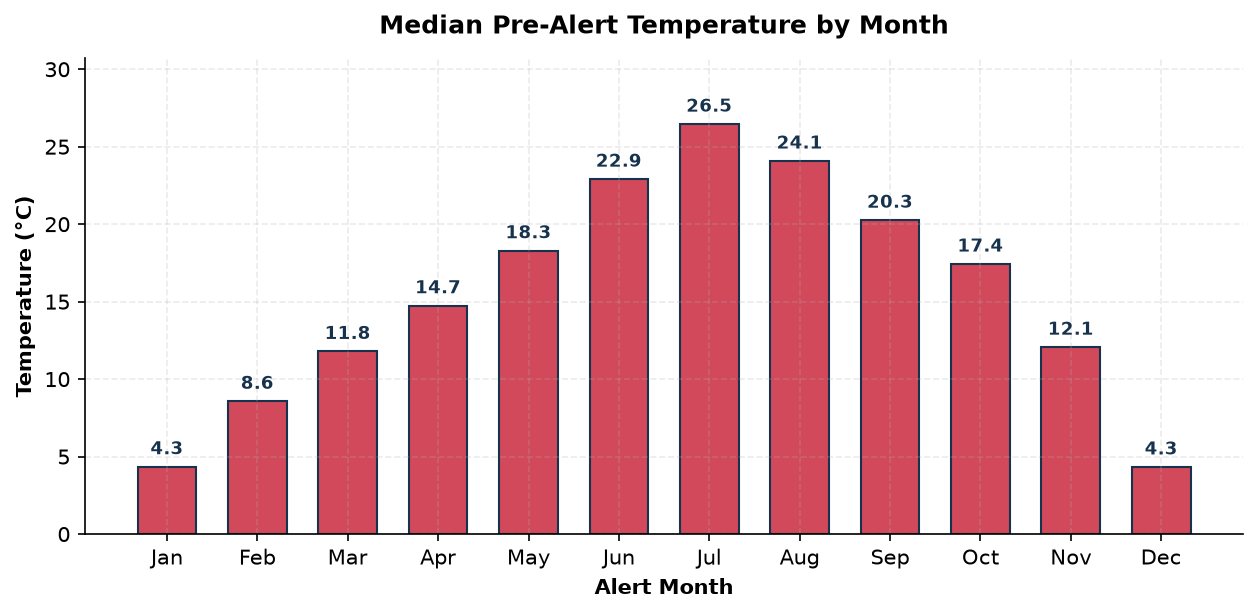

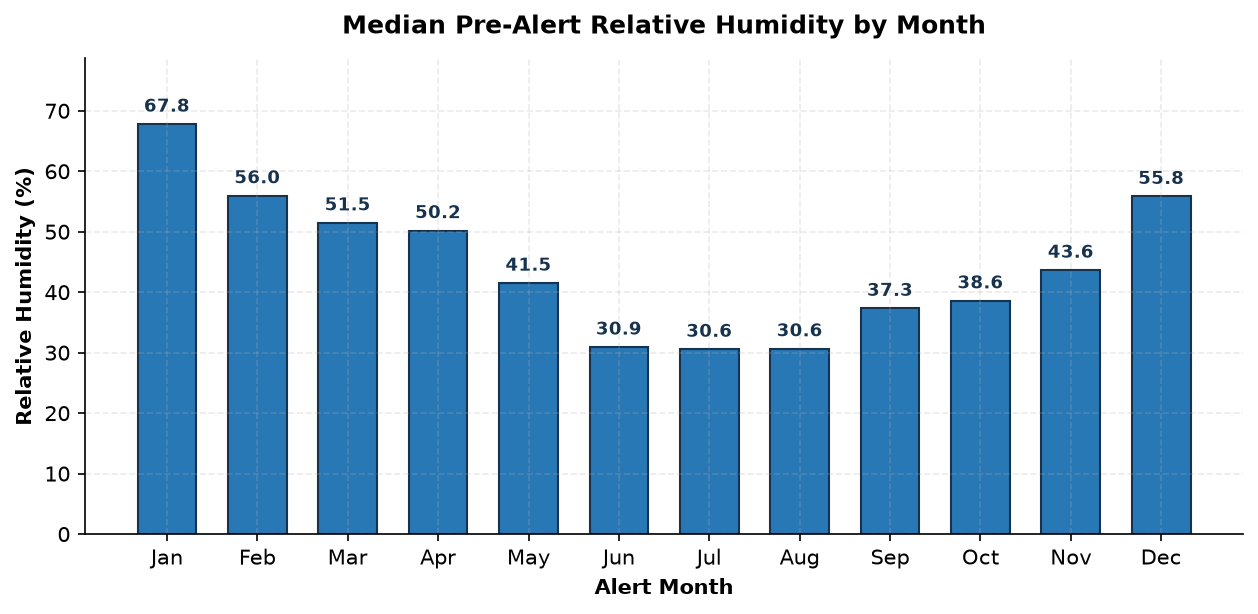

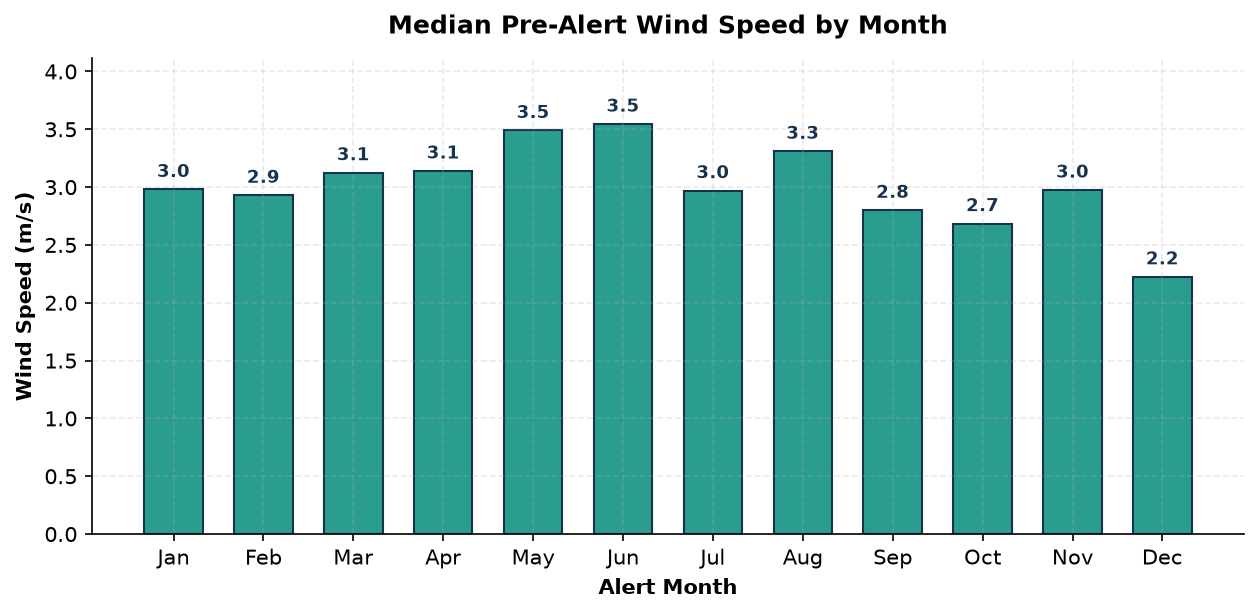

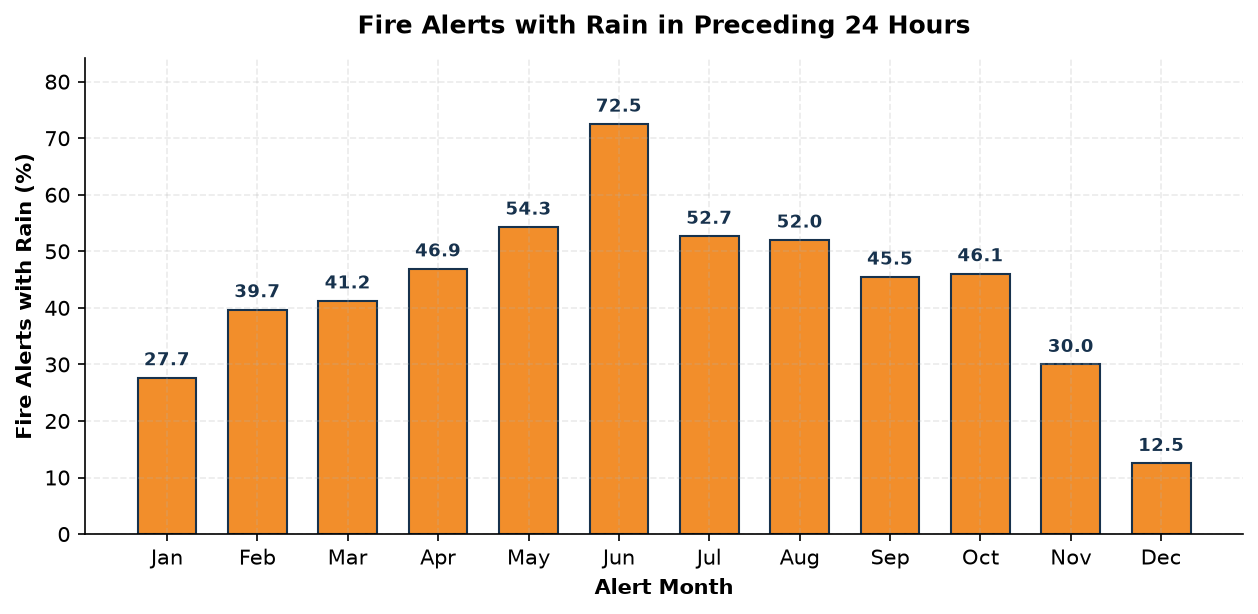

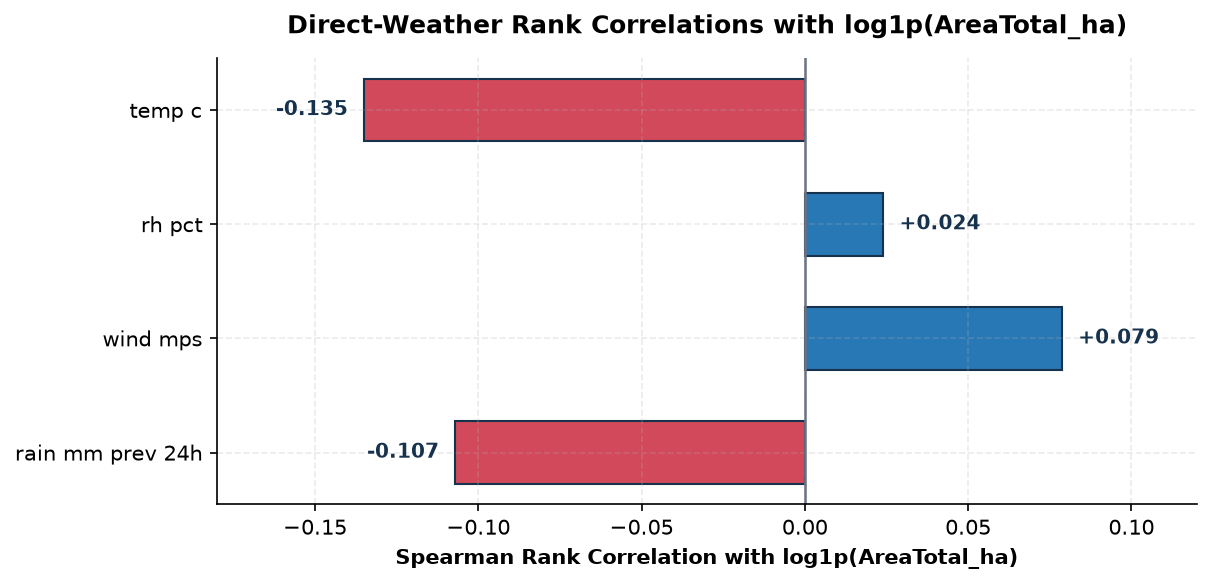

In [5]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly_charts = [
    ("median_temp_c", "weather_temperature_by_month.png", "Median Pre-Alert Temperature by Month", "Temperature (°C)", RED),
    ("median_rh_pct", "weather_rh_by_month.png", "Median Pre-Alert Relative Humidity by Month", "Relative Humidity (%)", BLUE),
    ("median_wind_mps", "weather_wind_by_month.png", "Median Pre-Alert Wind Speed by Month", "Wind Speed (m/s)", GREEN),
    ("wet_24h_pct", "weather_rain_by_month.png", "Fire Alerts with Rain in Preceding 24 Hours", "Fire Alerts with Rain (%)", ORANGE),
]

for field, filename, title, ylabel, color in monthly_charts:
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    values = weather_by_month[field].to_numpy(dtype=float)
    bars = ax.bar(month_labels, values, color=color, edgecolor=NAVY, width=0.65)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel(ylabel, fontsize=10, fontweight="bold")
    ax.set_xlabel("Alert Month", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(values) * 1.16)

    for bar, val in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.02,
            f"{val:.1f}",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color=NAVY,
            fontweight="bold",
        )

    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=300)
    plt.show()

# Plot horizontal bar chart of Spearman rank correlations with log1p(AreaTotal_ha)
fig, ax = plt.subplots(figsize=(8.2, 4.0))
corr_labels = [f.replace("weather_", "").replace("_", " ") for f in weather_correlations["feature"]]
corr_values = weather_correlations["spearman_with_log1p_area"].to_numpy(dtype=float)
bar_colors = [BLUE if val >= 0 else RED for val in corr_values]
y_pos = np.arange(len(corr_labels))

bars = ax.barh(y_pos, corr_values, color=bar_colors, edgecolor=NAVY, height=0.55)
ax.axvline(0.0, color=GREY, linewidth=1.2, linestyle="-")
ax.set_yticks(y_pos)
ax.set_yticklabels(corr_labels, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(-0.18, 0.12)
ax.set_xlabel("Spearman Rank Correlation with log1p(AreaTotal_ha)", fontsize=10, fontweight="bold")
ax.set_title("Direct-Weather Rank Correlations with log1p(AreaTotal_ha)", fontsize=12, fontweight="bold", pad=12)

for bar, val in zip(bars, corr_values):
    offset = 0.005 if val >= 0 else -0.005
    alignment = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{val:+.3f}",
        va="center",
        ha=alignment,
        fontsize=9.5,
        color=NAVY,
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig(FIGURE_DIR / "weather_target_correlations.png", dpi=300)
plt.show()


---
## 5. Alert-Time Feature Engineering and Leakage Exclusions


In [6]:
features = joined.copy()

# 1. Cyclic calendar and diurnal encodings
features["month_sin"] = np.sin(2 * np.pi * features["Mes"] / 12.0)
features["month_cos"] = np.cos(2 * np.pi * features["Mes"] / 12.0)

day_of_year = features["alert_time_local"].dt.dayofyear
features["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
features["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

decimal_hour = features["alert_time_local"].dt.hour + (features["alert_time_local"].dt.minute / 60.0)
features["hour_sin"] = np.sin(2 * np.pi * decimal_hour / 24.0)
features["hour_cos"] = np.cos(2 * np.pi * decimal_hour / 24.0)

# 2. Calendar weekend flag and spatial location features
features["is_weekend"] = features["alert_time_local"].dt.dayofweek.ge(5).astype(int)
features["municipality_vinhais"] = features["Concelho"].astype(str).str.casefold().eq("vinhais").astype(int)
features["x_etrs89_km"] = features["X_ETRS89"] / 1000.0
features["y_etrs89_km"] = features["Y_ETRS89"] / 1000.0

# 3. FWI and Weather missingness flags + log1p rainfall transformation
fwi_features = ["FFMC", "DMC", "DC", "ISI", "BUI", "FWI", "DSR"]
features["fwi_missing_flag"] = features[fwi_features].isna().any(axis=1).astype(int)
features["weather_missing_flag"] = features[model_weather_fields].isna().any(axis=1).astype(int)
features["weather_rain_prev_24h_log1p"] = np.log1p(features["weather_rain_mm_prev_24h"])

# 4. Target columns (raw hectares and log1p-transformed hectares)
features["target_area_ha"] = features["AreaTotal_ha"]
features["target_log1p_area"] = np.log1p(features["AreaTotal_ha"])

# 5. Define the two candidate feature sets
calendar_location_features = [
    "month_sin", "month_cos",
    "doy_sin", "doy_cos",
    "hour_sin", "hour_cos",
    "is_weekend",
    "municipality_vinhais",
    "x_etrs89_km", "y_etrs89_km",
]
sgif_only_features = calendar_location_features + fwi_features + ["fwi_missing_flag"]
weather_model_features = [
    "weather_temp_c",
    "weather_rh_pct",
    "weather_wind_mps",
    "weather_rain_prev_24h_log1p",
]
weather_enriched_features = sgif_only_features + weather_model_features + ["weather_missing_flag"]

# 6. Export feature definitions and leakage exclusion audit tables
feature_definitions = pd.DataFrame([
    ["month_sin/month_cos", "Calendar", "Cyclic alert month", "Yes", "Both"],
    ["doy_sin/doy_cos", "Calendar", "Cyclic day of year", "Yes", "Both"],
    ["hour_sin/hour_cos", "Calendar", "Cyclic local alert time", "Yes", "Both"],
    ["is_weekend", "Calendar", "Weekend indicator", "Yes", "Both"],
    ["municipality_vinhais", "Location", "Vinhais versus Braganca municipality", "Yes", "Both"],
    ["x_etrs89_km/y_etrs89_km", "Location", "Projected ignition coordinates in kilometres", "Yes", "Both"],
    [", ".join(fwi_features), "Fire weather indices", "SGIF FWI-family values", "Yes", "Both"],
    ["weather_temp_c", "Direct weather", "Last completed-hour temperature", "Yes", "Enriched only"],
    ["weather_rh_pct", "Direct weather", "Last completed-hour relative humidity", "Yes", "Enriched only"],
    ["weather_wind_mps", "Direct weather", "Last completed-hour wind speed", "Yes", "Enriched only"],
    ["weather_rain_prev_24h_log1p", "Direct weather", "log1p of rain over preceding 24 completed hours; application input remains raw mm", "Yes", "Enriched only"],
], columns=["feature", "group", "definition", "known_at_prediction", "feature_set"])
feature_definitions.to_csv(TABLE_DIR / "model_feature_definitions.csv", index=False)

leakage_audit = pd.DataFrame([
    ["AreaPov_ha, AreaMato_ha, AreaAgric_ha, ClasseArea", "Final outcome components/classes", "Excluded"],
    ["DataHora_PrimeiraIntervencao, DataHora_Extincao, Duracao_Horas", "Response/outcome timing after alert", "Excluded"],
    ["CodCausa, TipoCausa, GrupoCausa, DescricaoCausa", "Usually assigned after investigation", "Excluded"],
    ["IncSup24horas", "Post-event status", "Excluded"],
    ["Source workbook/sheet/row and audit flags", "Provenance rather than physical inputs", "Excluded"],
], columns=["fields", "reason", "decision"])
leakage_audit.to_csv(TABLE_DIR / "model_leakage_exclusion_audit.csv", index=False)

print("=" * 72)
print("CANDIDATE FEATURE SETS SUMMARY")
print("=" * 72)
print(f"SGIF-Only Baseline Features ({len(sgif_only_features)})       : {sgif_only_features}")
print(f"Weather-Enriched Features   ({len(weather_enriched_features)})       : {weather_enriched_features}")
print("\nFeature Definitions Table:")
display(feature_definitions)
print("\nPost-Ignition & Provenance Leakage Exclusion Audit:")
display(leakage_audit)


CANDIDATE FEATURE SETS SUMMARY
SGIF-Only Baseline Features (18)       : ['month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'hour_sin', 'hour_cos', 'is_weekend', 'municipality_vinhais', 'x_etrs89_km', 'y_etrs89_km', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'DSR', 'fwi_missing_flag']
Weather-Enriched Features   (23)       : ['month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'hour_sin', 'hour_cos', 'is_weekend', 'municipality_vinhais', 'x_etrs89_km', 'y_etrs89_km', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'DSR', 'fwi_missing_flag', 'weather_temp_c', 'weather_rh_pct', 'weather_wind_mps', 'weather_rain_prev_24h_log1p', 'weather_missing_flag']

Feature Definitions Table:


,feature,group,definition,known_at_prediction,feature_set
0,month_sin/month_cos,Calendar,Cyclic alert month,Yes,Both
1,doy_sin/doy_cos,Calendar,Cyclic day of year,Yes,Both
2,hour_sin/hour_cos,Calendar,Cyclic local alert time,Yes,Both
3,is_weekend,Calendar,Weekend indicator,Yes,Both
4,municipality_vinhais,Location,Vinhais versus Braganca municipality,Yes,Both
5,x_etrs89_km/y_etrs89_km,Location,Projected ignition coordinates in kilometres,Yes,Both
6,"FFMC, DMC, DC, ISI, BUI, FWI, DSR",Fire weather indices,SGIF FWI-family values,Yes,Both
7,weather_temp_c,Direct weather,Last completed-hour temperature,Yes,Enriched only
8,weather_rh_pct,Direct weather,Last completed-hour relative humidity,Yes,Enriched only
9,weather_wind_mps,Direct weather,Last completed-hour wind speed,Yes,Enriched only



Post-Ignition & Provenance Leakage Exclusion Audit:


,fields,reason,decision
0,"AreaPov_ha, AreaMato_ha, AreaAgric_ha, ClasseArea",Final outcome components/classes,Excluded
1,"DataHora_PrimeiraIntervencao, DataHora_Extincao, Duracao_Horas",Response/outcome timing after alert,Excluded
2,"CodCausa, TipoCausa, GrupoCausa, DescricaoCausa",Usually assigned after investigation,Excluded
3,IncSup24horas,Post-event status,Excluded
4,Source workbook/sheet/row and audit flags,Provenance rather than physical inputs,Excluded


---
## 6. Chronological Splits and Training-Only Preprocessing

CHRONOLOGICAL SPLIT SUMMARY (2004-2025)
Unassigned split rows : 0


,split,records,first_year,last_year,median_area_ha,mean_area_ha,maximum_area_ha,fires_ge_100ha,weather_missing_records,fwi_missing_records
0,train,1250,2004,2017,1.00,8.902,829.750,22,0,1
1,validation,207,2018,2021,1.00,11.039,1057.500,4,0,1
2,test,187,2022,2025,1.08,14.926,924.495,5,0,1



TRAINING-ONLY (2004-2017) IMPUTATION & SCALING PARAMETERS


,feature,training_median,training_mean_after_imputation,training_std_after_imputation
0,x_etrs89_km,105.177,105.649,15.605
1,y_etrs89_km,247.829,247.212,4.957
2,FFMC,89.417,88.137,6.013
3,DMC,49.494,66.408,54.916
4,DC,453.421,412.417,284.205
5,ISI,6.175,6.623,3.380
6,BUI,70.223,89.293,69.618
7,FWI,18.460,19.827,12.913
8,DSR,4.740,6.939,6.760
9,weather_temp_c,17.600,17.638,7.673


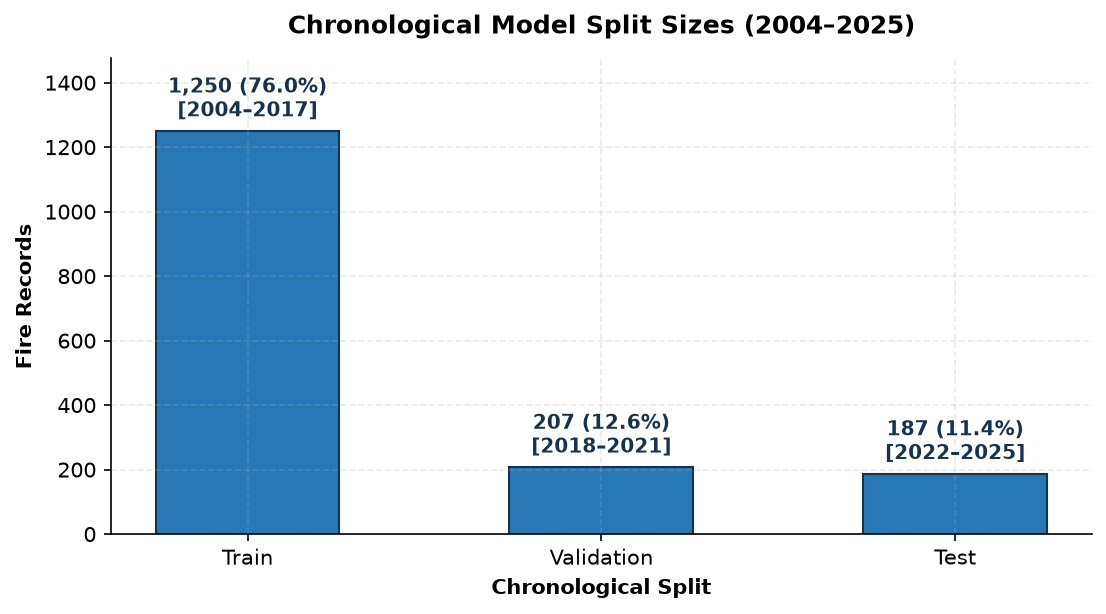

In [7]:
# 1. Assign chronological split labels
features["split"] = np.select(
    [
        features["Ano"].le(2017),
        features["Ano"].between(2018, 2021),
        features["Ano"].ge(2022),
    ],
    ["train", "validation", "test"],
    default="unassigned",
)

audit_columns = [
    "Codigo_SGIF",
    "Ano",
    "Mes",
    "alert_time_local",
    "alert_time_utc",
    "weather_reference_utc",
    "split",
    "target_area_ha",
    "target_log1p_area",
]

all_model_features = list(dict.fromkeys(weather_enriched_features))
unscaled = features[audit_columns + all_model_features].copy()
scaled = unscaled.copy()

# 2. Fit median imputation and Z-score scaling strictly on the 2004-2017 training split
continuous_features = ["x_etrs89_km", "y_etrs89_km"] + fwi_features + weather_model_features
training_mask = unscaled["split"].eq("train")

statistics = []
for field in continuous_features:
    training_values = pd.to_numeric(unscaled.loc[training_mask, field], errors="coerce")
    median_val = float(training_values.median())

    # Impute missing values in all splits using the training median only
    unscaled[field] = pd.to_numeric(unscaled[field], errors="coerce").fillna(median_val)

    # Compute mean and population std (ddof=0) on the imputed training split only
    mean_val = float(unscaled.loc[training_mask, field].mean())
    std_val = float(unscaled.loc[training_mask, field].std(ddof=0))
    if not np.isfinite(std_val) or std_val == 0.0:
        std_val = 1.0

    scaled[field] = (unscaled[field] - mean_val) / std_val
    statistics.append({
        "feature": field,
        "training_median": median_val,
        "training_mean_after_imputation": mean_val,
        "training_std_after_imputation": std_val,
    })

preprocessing_statistics = pd.DataFrame(statistics)
preprocessing_statistics.to_csv(TABLE_DIR / "preprocessing_training_statistics.csv", index=False)

# 3. Build chronological split summary table step-by-step
split_rows = []
for split_name in ["train", "validation", "test"]:
    subset = features[features["split"] == split_name]
    area_col = subset["AreaTotal_ha"]
    split_rows.append({
        "split": split_name,
        "records": int(len(subset)),
        "first_year": int(subset["Ano"].min()),
        "last_year": int(subset["Ano"].max()),
        "median_area_ha": float(area_col.median()),
        "mean_area_ha": float(area_col.mean()),
        "maximum_area_ha": float(area_col.max()),
        "fires_ge_100ha": int((area_col >= 100.0).sum()),
        "weather_missing_records": int(subset["weather_missing_flag"].sum()),
        "fwi_missing_records": int(subset["fwi_missing_flag"].sum()),
    })

split_summary = pd.DataFrame(split_rows)
split_summary.to_csv(TABLE_DIR / "model_temporal_split_summary.csv", index=False)

print("=" * 72)
print("CHRONOLOGICAL SPLIT SUMMARY (2004-2025)")
print("=" * 72)
print(f"Unassigned split rows : {int((features['split'] == 'unassigned').sum())}")
display(split_summary)

print("\n" + "=" * 72)
print("TRAINING-ONLY (2004-2017) IMPUTATION & SCALING PARAMETERS")
print("=" * 72)
display(preprocessing_statistics)

# 4. Plot chronological split counts using standard matplotlib
fig, ax = plt.subplots(figsize=(7.5, 4.2))
split_labels = [s.title() for s in split_summary["split"]]
split_counts = split_summary["records"].to_numpy(dtype=int)

bars = ax.bar(split_labels, split_counts, color=BLUE, edgecolor=NAVY, width=0.52)
ax.set_title("Chronological Model Split Sizes (2004–2025)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Fire Records", fontsize=10, fontweight="bold")
ax.set_xlabel("Chronological Split", fontsize=10, fontweight="bold")
ax.set_ylim(0, max(split_counts) * 1.18)

for bar, count, first_yr, last_yr in zip(
    bars, split_counts, split_summary["first_year"], split_summary["last_year"]
):
    pct = (count / len(features)) * 100.0
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(split_counts) * 0.02,
        f"{count:,} ({pct:.1f}%)\n[{first_yr}–{last_yr}]",
        ha="center",
        va="bottom",
        fontsize=9.5,
        color=NAVY,
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig(FIGURE_DIR / "model_temporal_split_counts.png", dpi=300)
plt.show()


---
## 7. Save Model-Ready Datasets and Feature Metadata

In [8]:
saved_files = []
for version_name, frame in [("unscaled", unscaled), ("scaled", scaled)]:
    all_path = PROCESSED_DIR / f"montesinho_model_ready_{version_name}_all.csv"
    frame.to_csv(all_path, index=False)
    saved_files.append(all_path)
    for split_name in ["train", "validation", "test"]:
        split_path = PROCESSED_DIR / f"montesinho_model_ready_{version_name}_{split_name}.csv"
        frame.loc[frame["split"].eq(split_name)].to_csv(split_path, index=False)
        saved_files.append(split_path)

feature_metadata = {
    "target_raw": "target_area_ha",
    "target_transformed": "target_log1p_area",
    "split_column": "split",
    "split_years": {"train": "2004-2017", "validation": "2018-2021", "test": "2022-2025"},
    "sgif_only_features": sgif_only_features,
    "weather_enriched_features": weather_enriched_features,
    "continuous_scaled_features": continuous_features,
    "imputation_and_scaling": "Training-period medians, means, and population standard deviations only",
    "weather_join": "Most recent fully completed NASA POWER UTC hour; rainfall accumulated over preceding 24 completed hours",
    "application_to_model_transform": {"rain_input_mm_previous_24h": "log1p -> weather_rain_prev_24h_log1p"},
}

metadata_path = PROCESSED_DIR / "model_feature_sets.json"
metadata_path.write_text(json.dumps(feature_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
saved_files.append(metadata_path)

print("=" * 72)
print(f"EXPORTED {len(saved_files)} PROCESSED ARTIFACTS TO {PROCESSED_DIR.as_posix()}")
print("=" * 72)
for path in saved_files:
    rel_path = path.relative_to(PROJECT_ROOT).as_posix()
    print(f" - {rel_path}")


EXPORTED 9 PROCESSED ARTIFACTS TO data/processed/icnf_sgif
 - data/processed/icnf_sgif/montesinho_model_ready_unscaled_all.csv
 - data/processed/icnf_sgif/montesinho_model_ready_unscaled_train.csv
 - data/processed/icnf_sgif/montesinho_model_ready_unscaled_validation.csv
 - data/processed/icnf_sgif/montesinho_model_ready_unscaled_test.csv
 - data/processed/icnf_sgif/montesinho_model_ready_scaled_all.csv
 - data/processed/icnf_sgif/montesinho_model_ready_scaled_train.csv
 - data/processed/icnf_sgif/montesinho_model_ready_scaled_validation.csv
 - data/processed/icnf_sgif/montesinho_model_ready_scaled_test.csv
 - data/processed/icnf_sgif/model_feature_sets.json


---
## 8. Saved-File and Leakage Verification


In [9]:
unscaled_finite = bool(np.isfinite(unscaled[all_model_features].to_numpy(dtype=float)).all())
scaled_finite = bool(np.isfinite(scaled[all_model_features].to_numpy(dtype=float)).all())
train_max_year = int(unscaled.loc[unscaled["split"].eq("train"), "Ano"].max())
val_min_year = int(unscaled.loc[unscaled["split"].eq("validation"), "Ano"].min())
val_max_year = int(unscaled.loc[unscaled["split"].eq("validation"), "Ano"].max())
test_min_year = int(unscaled.loc[unscaled["split"].eq("test"), "Ano"].min())

verification_rows = []
for path in saved_files:
    rel_file = path.relative_to(PROJECT_ROOT).as_posix()
    file_exists = path.exists()
    file_bytes = path.stat().st_size if file_exists else 0
    verification_rows.append({
        "file": rel_file,
        "exists": file_exists,
        "bytes": file_bytes,
    })

verification = pd.DataFrame(verification_rows)
verification.to_csv(TABLE_DIR / "processed_file_verification.csv", index=False)

print("=" * 72)
print("FINAL PREPROCESSING & INTEGRITY VERIFICATION")
print("=" * 72)
print(f"Unscaled / Scaled row count : {len(unscaled):,} / {len(scaled):,}")
print(f"Unique & aligned SGIF IDs   : {bool(unscaled['Codigo_SGIF'].is_unique and unscaled['Codigo_SGIF'].equals(scaled['Codigo_SGIF']))}")
print(f"All 23 unscaled finite      : {unscaled_finite}")
print(f"All 23 scaled finite        : {scaled_finite}")
print(f"Chronological boundaries    : Train <= {train_max_year} | Validation {val_min_year}-{val_max_year} | Test >= {test_min_year}")
print(f"Verified processed files    : {len(verification)} files (all exist = {bool(verification['exists'].all())})")
display(verification)


FINAL PREPROCESSING & INTEGRITY VERIFICATION
Unscaled / Scaled row count : 1,644 / 1,644
Unique & aligned SGIF IDs   : True
All 23 unscaled finite      : True
All 23 scaled finite        : True
Chronological boundaries    : Train <= 2017 | Validation 2018-2021 | Test >= 2022
Verified processed files    : 9 files (all exist = True)


,file,exists,bytes
0,data/processed/icnf_sgif/montesinho_model_ready_unscaled_all.csv,True,695763
1,data/processed/icnf_sgif/montesinho_model_ready_unscaled_train.csv,True,526464
2,data/processed/icnf_sgif/montesinho_model_ready_unscaled_validation.csv,True,88941
3,data/processed/icnf_sgif/montesinho_model_ready_unscaled_test.csv,True,81088
4,data/processed/icnf_sgif/montesinho_model_ready_scaled_all.csv,True,817258
5,data/processed/icnf_sgif/montesinho_model_ready_scaled_train.csv,True,618716
6,data/processed/icnf_sgif/montesinho_model_ready_scaled_validation.csv,True,104128
7,data/processed/icnf_sgif/montesinho_model_ready_scaled_test.csv,True,95144
8,data/processed/icnf_sgif/model_feature_sets.json,True,1647
